# A frozen-encoder router

**Part 3 of "LLMs the Hard Way"** (branch `frozen-router`). `01_modernbert_by_hand.ipynb` built ModernBERT's forward pass by hand and showed that a fixed classification head can't handle agents that change. This notebook keeps the encoder **frozen** and turns it into a **multi-agent router**: each candidate agent is read together with the conversation, and a small trained head scores how well they fit.

```text
chat history + current agent + Agent A  →  encoder  →  head  →  score A
chat history + current agent + Agent B  →  encoder  →  head  →  score B      →  softmax  →  chosen agent
...
```

Agents are just names and descriptions, so they can change at any time without retraining.

**The final design** (the best frozen system, runs 10–17):

```text
ModernBERT-large → pooled spans → MLP-256 → p(topic changed)
   p < τ  → keep the current agent
   p ≥ τ  → Nemotron-1B (cross + dual passes) → matching features → MLP-256 → one agent
```

It beat the 2B Strands decider on routing in conversations at unseen companies (74 / 83 against 62 with full history), but general choice questions plateaued at 114 / 170 against the decider's 160. **The frozen encoder was the limit**, and the last section shows the evidence. `03_lora_signpost.ipynb` (branch `signpost`) fine-tunes the encoder with LoRA and closes that gap.

| Section | Cells | Topic |
|---|---|---|
| Data and encoders | 1–3 | setup, training and test data, two frozen encoders, one input format |
| Training | 4–8 | routing and general questions as option pairs, frozen features, the head, leave-domains-out folds, the final heads |
| Routing | 9–12 | one banking conversation scored live, the banking tests, E11 (first messages), E10 (whole conversations) |
| The gate | 13–16 | a yes / no "has the topic changed?" detector, and the confident-stay gate |
| Questions | 17 | E12: grounded choice questions |
| Results | 18 | summary, and what we tried and dropped |

**Runs on:** Kaggle with a GPU (T4 or better). Data comes from this branch (`data/modernbert_router/`). The experiment ledger (`experiments/modernbert_router_ledger.md`, runs 5–17) records every run at its own commit and data. This notebook runs the final state, so its numbers will be close to run 17's, not identical.

**Settings** (environment variables, all optional):

| Setting | Default | Meaning |
|---|---|---|
| `ROUTER_ENCODER` | `nemotron-1b` | the router's encoder: `nemotron-1b` or `modernbert` |
| `DETECTOR_ENCODER` | `modernbert` | the context-change detector's encoder |
| `REALISTIC_TRAIN` | 1 | add the free-form realistic training conversations |
| `CHOICE_TRAIN` | 1 | train the choice head on general questions |
| `ROUTER_MAX_EPOCHS` | 400 | maximum head epochs (early stopping decides) |
| `ROUTER_SUBSAMPLE`, `ROUTER_SMOKE` | off | code checks only: fewer training conversations, small test sets |

In [22]:
# Cell 1 — Setup: packages, settings, device, progress log

!pip install -q "transformers==5.17.0"

import copy
import json
import os
import random
import statistics
import subprocess
import sys
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

ROUTER_ENCODER = os.environ.get("ROUTER_ENCODER", "nemotron-1b")      # the router's encoder
DETECTOR_ENCODER = os.environ.get("DETECTOR_ENCODER", "modernbert")   # the context-change detector's encoder
REALISTIC_TRAIN = os.environ.get("REALISTIC_TRAIN", "1") == "1"       # add the free-form realistic training conversations
CHOICE_TRAIN = os.environ.get("CHOICE_TRAIN", "1") == "1"             # train the choice head on general questions
MAX_EPOCHS = int(os.environ.get("ROUTER_MAX_EPOCHS", "400"))          # head epochs; early stopping decides
ROUTER_SUBSAMPLE = int(os.environ.get("ROUTER_SUBSAMPLE", "0"))       # code check: this many conversations per domain
ROUTER_SMOKE = os.environ.get("ROUTER_SMOKE") == "1"                  # code check: small test sets; never for a real run

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RUN_LOG = Path("router_run.log")


def log(message):
    """Print a timestamped progress line and append it to router_run.log."""
    line = f"[{time.strftime('%H:%M:%S')}] {message}"
    print(line, flush=True)
    with open(RUN_LOG, "a") as fh:
        fh.write(line + "\n")


def mem():
    """Host RAM used by this process and GPU memory allocated, for the progress log."""
    import psutil
    gpu = f" | GPU {torch.cuda.memory_allocated() / 1e9:.1f} GB" if torch.cuda.is_available() else ""
    return f"RAM {psutil.Process().memory_info().rss / 1e9:.1f} GB{gpu}"


print("Python :", sys.version.split()[0], "| PyTorch:", torch.__version__)
log(f"router run started on {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "") + f" | {mem()}")

Python : 3.13.15 | PyTorch: 2.11.0+cu128
[16:00:28] router run started on cuda (Tesla T4) | RAM 5.5 GB | GPU 4.2 GB


---
# Data and encoders

## Cell 2 — Data

The router trains **only on conversations from other domains** and is tested on companies and agents it has never seen. If it routes those correctly, it has learned how a conversation fits an agent *description*, not a fixed set of agents.

| File (`data/modernbert_router/`) | Role |
|---|---|
| `generic/` | training: template conversations from non-banking domains, 5 agents each (one close pair, one general agent) |
| `realistic_train/` | training: free-form conversations from other businesses |
| `choice_train/items.json` | training, choice head only: yes / no, choice and score questions about short texts |
| `banking/` | test: 50 benchmark + 175 extended banking conversations |
| `first_turn/messages.json` | test E11: 100 first messages, 10 companies × 5 agents |
| `realistic/conversations.json` | test E10: 35 conversations, 13 companies, 193 labelled user turns |
| `choice_test/items.json` | test E12: 170 grounded questions |

Every conversation records its **current agent**, the agent that spoke the last assistant message (none at the start). It is often *not* the right answer, after a handoff or a topic change, so the router must learn when to stay and when to switch.

**Expect.** The data sizes, the training domains, a check that no training conversation mentions a banking agent, and one example.

In [23]:
# Cell 2a — Load the training data and every test set

DATA_BRANCH = "frozen-router"
DATA_DIR = Path("data/modernbert_router")
if not DATA_DIR.exists():                     # on Kaggle / Colab: clone this branch (an existing clone is refreshed)
    repo = Path("llms-the-hard-way")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", DATA_BRANCH,
                        "https://github.com/skamalj/llms-the-hard-way.git", str(repo)], check=True)
    else:
        subprocess.run(["git", "-C", str(repo), "fetch", "--depth", "1", "origin", DATA_BRANCH], check=True)
        subprocess.run(["git", "-C", str(repo), "checkout", "-B", DATA_BRANCH, "FETCH_HEAD"], check=True)
    DATA_DIR = repo / "data" / "modernbert_router"
print("data folder:", DATA_DIR.resolve(), "| branch:", DATA_BRANCH)


def load(path):
    with open(path) as f:
        return json.load(f)


# training
generic_domains = load(DATA_DIR / "generic" / "domains.json")
generic_conversations = load(DATA_DIR / "generic" / "conversations.json")
if REALISTIC_TRAIN:
    realistic_domains = load(DATA_DIR / "realistic_train" / "domains.json")
    assert not set(realistic_domains) & set(generic_domains)
    generic_domains = {**generic_domains, **realistic_domains}
    generic_conversations += load(DATA_DIR / "realistic_train" / "conversations.json")
if ROUTER_SUBSAMPLE:                          # evenly spread over each domain
    by_domain = {}
    for ex in generic_conversations:
        by_domain.setdefault(ex["domain"], []).append(ex)
    generic_conversations = [convs[i * len(convs) // ROUTER_SUBSAMPLE] for convs in by_domain.values() for i in range(ROUTER_SUBSAMPLE)]
choice_train = load(DATA_DIR / "choice_train" / "items.json")["items"] if CHOICE_TRAIN else []
if ROUTER_SUBSAMPLE or ROUTER_SMOKE:
    choice_train = choice_train[::25]

# tests
banking_benchmark = load(DATA_DIR / "banking" / "benchmark.json")
banking_extended = load(DATA_DIR / "banking" / "extended.json")
ft = load(DATA_DIR / "first_turn" / "messages.json")                  # E11
real_convs = load(DATA_DIR / "realistic" / "conversations.json")      # E10
e12_items = load(DATA_DIR / "choice_test" / "items.json")["items"]    # E12
if ROUTER_SMOKE:
    banking_benchmark, banking_extended, real_convs, e12_items = banking_benchmark[:10], banking_extended[:5], real_convs[:3], e12_items[:12]
ft_companies, ft_msgs = ft["companies"], ft["messages"]

print(f"training: {len(generic_domains)} domains, {len(generic_conversations)} conversations | {len(choice_train)} general questions ("
      + ", ".join(f"{t} {n}" for t, n in Counter(x["type"] for x in choice_train).items()) + ")")
print(f"tests: banking {len(banking_benchmark)} + {len(banking_extended)} | E11 {len(ft_msgs)} first messages | "
      f"E10 {len(real_convs)} conversations, {sum(len(c['user_turns']) for c in real_convs)} turns | E12 {len(e12_items)} questions")

Your branch is up to date with 'origin/frozen-router'.
data folder: /kaggle/working/llms-the-hard-way/data/modernbert_router | branch: frozen-router
training: 77 domains, 6850 conversations | 10600 general questions (noul 5620, choice 2832, score 2148)
tests: banking 50 + 175 | E11 100 first messages | E10 35 conversations, 193 turns | E12 170 questions


From https://github.com/skamalj/llms-the-hard-way
 * branch            frozen-router -> FETCH_HEAD
Reset branch 'frozen-router'


In [24]:
# Cell 2b — Checks, the training domains and one example

for ex in generic_conversations + banking_benchmark + banking_extended:
    assert "current_agent" in ex, ex["id"]
    roles = [m["role"] for m in ex["messages"]]
    assert 1 <= len(roles) <= 15 and roles[0] == "user" and roles[-1] == "user", ex["id"]
    assert all(r1 != r2 for r1, r2 in zip(roles, roles[1:])), "roles alternate"
assert all("context_change" in ex for ex in generic_conversations)

banking_names = ["payments agent", "card support", "investment agent", "insurance agent", "general customer support"]
leaks = [ex["id"] for ex in generic_conversations
         if any(w in " ".join(m["content"].lower() for m in ex["messages"]) for w in banking_names)]
assert not leaks, leaks
print("No training conversation mentions a banking agent.\n")

print(f"{'domain':24s} | {'conversations':>13} | agents (close pair marked *)")
for dom, info in generic_domains.items():
    n = sum(ex["domain"] == dom for ex in generic_conversations)
    print(f"{dom:24s} | {n:>13} | " + ", ".join(a + ("*" if a in info["close_pair"] else "") for a in info["agents"]))

example = next((ex for ex in generic_conversations if "ok_after_handoff" in ex["tags"] and len(ex["messages"]) == 5),
               generic_conversations[0])
print(f"\nexample {example['id']} (tags {example['tags']}):")
for m in example["messages"]:
    print(f"  {m['role']:9s}: {m['content']}")
print(f"  -> current agent: {example['current_agent']} | target agent: {example['target_agent']}")
stay = sum(ex["current_agent"] == ex["target_agent"] for ex in generic_conversations)
fresh = sum(ex["current_agent"] is None for ex in generic_conversations)
print(f"\ncurrent agent: none {fresh} | target = current (stay) {stay} | target != current (switch) {len(generic_conversations) - stay - fresh}")

No training conversation mentions a banking agent.

domain                   | conversations | agents (close pair marked *)
it_helpdesk              |           220 | Password & Access Agent*, Network & VPN Agent*, Hardware Agent, Software Installation Agent, General IT Support Agent
hr                       |           221 | Leave & Holidays Agent, Recruitment Agent*, Onboarding Agent*, Training & Learning Agent, General HR Support Agent
airline                  |           222 | Flight Booking Agent*, Check-in & Seating Agent*, Baggage Agent, Special Assistance Agent, General Travel Support Agent
clinic                   |           221 | Appointments Agent, Prescriptions Agent*, Pharmacy Delivery Agent*, Lab Results Agent, General Patient Support Agent
food_delivery            |           221 | Order Status Agent*, Delivery Address Agent*, Restaurant & Menu Agent, App Settings Agent, General Customer Help Agent
university               |           218 | Admissions Agent, Course Regi

## Cell 3 — Two frozen encoders, one input format

The router and the context-change detector each read text through **their own encoder**. The final design uses **Nemotron-1B** (`nvidia/llama-nemotron-embed-1b-v2`, a bidirectional Llama trained for retrieval, with `query:` / `passage:` prefixes) for the router, and **ModernBERT-large**, whose forward pass 01 rebuilt by hand, for the detector. Both run through the library `AutoModel`, and both stay **frozen**: none of their weights is trained.

Every question, routing included, becomes one text (the separator is `[SEP]` for ModernBERT and a newline for Nemotron):

```text
user: … [SEP] assistant: … [SEP] user: … [SEP] current agent: X [SEP] question: Q [SEP] candidate: <name>. <description>
```

`build_text` records the **character range** of every part. The tokenizer's offset mapping turns the ranges of a batch into one token mask `M [B, spans, T]`, for any tokenizer, and `span_means` mean-pools every span at once, `M @ hidden / count` (01, Cell 13's mean pooling as a matrix product), caching the result by text.

**Expect.** Both encoders with 0 trainable parameters, and one router input with the character range of every part.

In [25]:
# Cell 3a — The two encoders (each loaded once), frozen

ENCODERS = {
    # ModernBERT-large in float32, as in 01; " [SEP] " is its separator token
    "modernbert":  {"checkpoint": "answerdotai/ModernBERT-large", "trust_remote_code": False, "dtype": torch.float32,
                    "sep": " [SEP] ", "query": "", "passage": ""},
    # a bidirectional Llama-3.2-1B trained for retrieval with these prefixes; fp16 on the GPU
    "nemotron-1b": {"checkpoint": "nvidia/llama-nemotron-embed-1b-v2", "trust_remote_code": True, "dtype": None,
                    "sep": "\n", "query": "query: ", "passage": "passage: "},
}


class TextEncoder:
    """One frozen encoder: its tokenizer, text format (separator, prefixes) and forward pass."""

    def __init__(self, key):
        spec = ENCODERS[key]
        self.key, self.name = key, spec["checkpoint"]
        self.sep, self.query, self.passage = spec["sep"], spec["query"], spec["passage"]
        self.tokenizer = AutoTokenizer.from_pretrained(self.name, trust_remote_code=spec["trust_remote_code"])
        self.tokenizer.padding_side = "right"
        if self.tokenizer.pad_token is None:
            self.tokenizer.pad_token = self.tokenizer.eos_token
        dtype = spec["dtype"] or (torch.float16 if DEVICE.type == "cuda" else torch.float32)
        self.model = AutoModel.from_pretrained(self.name, trust_remote_code=spec["trust_remote_code"], dtype=dtype).to(DEVICE).eval()
        self.model.requires_grad_(False)                         # frozen: no gradients, nothing trained
        self.tag = self.name.split("/")[-1]                      # names this encoder's feature caches

    def run(self, input_ids, attention_mask):
        """-> the last layer's output [B, T, H] in float32."""
        return self.model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state.float()


_ENCODER_INSTANCES = {}


def get_encoder(key):
    """Load each encoder once, even when the router and the detector use the same one."""
    if key not in _ENCODER_INSTANCES:
        _ENCODER_INSTANCES[key] = TextEncoder(key)
    return _ENCODER_INSTANCES[key]


ROUTER_ENC, DETECTOR_ENC = get_encoder(ROUTER_ENCODER), get_encoder(DETECTOR_ENCODER)
for role, enc in [("router", ROUTER_ENC), ("detector", DETECTOR_ENC)]:
    n = sum(p.numel() for p in enc.model.parameters())
    trainable = sum(p.numel() for p in enc.model.parameters() if p.requires_grad)
    print(f"{role:8s} encoder: {enc.name} | {n / 1e6:.0f} M parameters, {trainable} trainable | "
          f"H = {getattr(enc.model.config, 'hidden_size', '?')}")
print(f"one shared instance: {ROUTER_ENC is DETECTOR_ENC} | {mem()}")

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-large
Key               | Status     |  | 
------------------+------------+--+-
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 
decoder.bias      | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


router   encoder: nvidia/llama-nemotron-embed-1b-v2 | 1236 M parameters, 0 trainable | H = 2048
detector encoder: answerdotai/ModernBERT-large | 395 M parameters, 0 trainable | H = 1024
one shared instance: False | RAM 5.9 GB | GPU 4.2 GB


In [26]:
# Cell 3b — One text per (conversation, question, option), and mean-pooled spans by character range

ROUTE_Q = "Which agent should handle the user's latest message?"
MAX_MESSAGES = 15
BATCH = 32 if DEVICE.type == "cuda" else 8
CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)
timing = {"encoder_passes": 0, "encoder_seconds": 0.0}


def build_text(messages, current=None, candidate=None, prefix="", enc=None, question=None):
    """prefix + msg_1 SEP ... SEP "current agent: X" [SEP "question: Q"] [SEP "candidate: <option>"] in encoder enc's
    format (default: the router's) -> (text, the character range of every part). Without a question (the detector's
    input) the candidate is written "candidate agent: ..."."""
    sep = (enc or ROUTER_ENC).sep
    assert 1 <= len(messages) <= MAX_MESSAGES
    text, spans = prefix, {"messages": [], "current": None, "question": None, "candidate": None}
    for k, m in enumerate(messages):
        text += sep if k else ""
        seg = f"{m['role']}: {m['content']}"
        spans["messages"].append((len(text), len(text) + len(seg))); text += seg
    cand_label = "candidate agent" if question is None else "candidate"
    for key, seg in [("current", f"current agent: {current or 'none'}"),
                     ("question", None if question is None else f"question: {question}"),
                     ("candidate", None if candidate is None else f"{cand_label}: {candidate}")]:
        if seg is not None:
            text += sep
            spans[key] = (len(text), len(text) + len(seg)); text += seg
    return text, spans


def span_masks(offsets, attention, ranges):
    """-> [B, S, T]: which real tokens overlap each character range (start, end); a None range = every real token."""
    s, e = offsets[..., 0], offsets[..., 1]                                        # [B, T]
    real = attention.bool() & (e > s)
    r = torch.tensor([[rg or (0, 10 ** 9) for rg in rs] for rs in ranges])         # [B, S, 2]
    m = real[:, None] & (s[:, None] < r[..., 1:]) & (e[:, None] > r[..., :1])      # [B, S, T]
    return torch.where(m.any(-1, keepdim=True), m, real[:, None].expand_as(m))     # never an empty span


def span_means(texts, ranges, cache, cache_file, title, enc=None, save=True):
    """Mean of the encoder's last-layer token vectors over each character range, cached by text (and saved to
    cache_file after a big run if save). texts: N strings; ranges: N lists of S ranges -> [N, S, H]."""
    enc = enc or ROUTER_ENC
    todo = [t for t in dict.fromkeys(texts) if t not in cache]
    if todo:
        rng_of = dict(zip(texts, ranges))
        t0, verbose = time.perf_counter(), len(todo) >= 500          # log only the big feature runs, not live routing
        if verbose:
            log(f"{title}: {len(todo)} new encoder passes ({enc.name})")
        order = sorted(todo, key=len)                                # similar lengths together: less padding
        for start in range(0, len(order), BATCH):
            if verbose and start and start % (BATCH * 100) == 0:
                el = time.perf_counter() - t0
                log(f"  {title} {start}/{len(todo)} | {start / el:.0f} texts/s | ~{(len(todo) - start) / (start / el):.0f}s left")
            chunk = order[start:start + BATCH]
            batch = enc.tokenizer(chunk, padding=True, return_tensors="pt", return_offsets_mapping=True)
            offs, attn = batch.pop("offset_mapping"), batch["attention_mask"]
            with torch.no_grad():
                hidden = enc.run(batch["input_ids"].to(DEVICE), attn.to(DEVICE))
            assert torch.isfinite(hidden).all(), f"{enc.name} produced inf/NaN (fp16 overflow?)"
            M = span_masks(offs, attn, [rng_of[t] for t in chunk]).to(DEVICE, hidden.dtype)        # [B, S, T]
            pooled = (M @ hidden) / M.sum(-1, keepdim=True)                                       # [B, S, H]
            cache.update(zip(chunk, pooled.half().cpu()))
        timing["encoder_passes"] += len(todo); timing["encoder_seconds"] += time.perf_counter() - t0
        if verbose and save:                                         # persist big training runs; tests stay in memory
            torch.save(cache, cache_file)
        if verbose:
            log(f"{title} done: {len(todo)} passes in {time.perf_counter() - t0:.0f}s")
    return torch.stack([cache[t] for t in texts]).float()


demo_text, demo_spans = build_text(example["messages"], example["current_agent"], "Some Agent. Handles something.",
                                   ROUTER_ENC.query, question=ROUTE_Q)
print(f"router input ({ROUTER_ENCODER}):\n{demo_text}\n")
for part, rng in demo_spans.items():
    print(f"  {part:9s} {rng}")

router input (nemotron-1b):
query: user: I can't reach the system from home.
assistant: Does it reject your login, or does the connection not come up at all?
user: it rejects my login
assistant: The Password & Access Agent handles this. Please continue with that agent.
user: Okay.
current agent: General IT Support Agent
question: Which agent should handle the user's latest message?
candidate: Some Agent. Handles something.

  messages  [(7, 48), (49, 129), (130, 155), (156, 241), (242, 253)]
  current   (254, 293)
  question  (294, 356)
  candidate (357, 398)


---
# Training

## Cell 4 — Two heads, two kinds of question

Routing and general questions share the input format and the frozen encoder, but each gets **its own head**, with no shared training data, folds or statistics:

| | Route head | Choice head |
|---|---|---|
| Training | routing conversations: "Which agent should handle the user's latest message?" | questions about a short text: yes / no, choice, score |
| Tests | banking, E11, E10 | E12 |

A question becomes one **pair** per option. The folds leave whole **domains** out, so a head is always scored on agents (or question families) it has never seen. Every routing domain has a deliberate **close pair** of agents (Password & Access vs Network & VPN), like Payments vs Card Support in banking; the pair types show how many of the wrong options are that hard.

**Expect.** Questions, pairs and fold sizes per head, the pair types, and one serialized example per question type.

In [27]:
# Cell 4 — Routing and general questions as (question, option) pairs; leave-domains-out folds per head

K_MAX = 5                                                   # options per question: 2 (yes / no) up to 5 (agents)


def option_text(name, description):
    return f"{name}. {description}" if description else name


route_examples = [{"id": ex["id"], "domain": ex["domain"], "task": "routing", "messages": ex["messages"], "current": ex["current_agent"],
                   "question": ROUTE_Q, "options": generic_domains[ex["domain"]]["agents"], "target": ex["target_agent"]}
                  for ex in generic_conversations]
choice_examples = [{"id": it["id"], "domain": it["domain"], "task": it["type"], "messages": [{"role": "user", "content": it["state"]}],
                    "current": None, "question": it["question"], "options": {o: "" for o in it["options"]}, "target": it["answer"]}
                   for it in choice_train]
train_examples = route_examples + choice_examples          # encoded together (the encoder is frozen); trained apart
ex_group = ["route"] * len(route_examples) + ["choice"] * len(choice_examples)
conv_domain = [ex["domain"] for ex in train_examples]
ex_task = [ex["task"] for ex in train_examples]
GROUPS = ["route", "choice"] if choice_examples else ["route"]


def pair_type(ex, name):
    """How hard a wrong routing option is: the close-pair sibling, an agent whose keyword appears, or obviously wrong."""
    if name == ex["target"]:
        return "positive"
    if ex["task"] != "routing":
        return "other question"
    info = generic_domains[ex["domain"]]
    if {name, ex["target"]} == set(info["close_pair"]):
        return "semantically close"
    text = " ".join(m["content"] for m in ex["messages"]).lower()
    return "plausible but incorrect" if any(k in text for k in info["keywords"][name]) else "obviously wrong"


generic_pairs = []                                          # one per option; ex / slot place it on the [questions, K_MAX] grid
for ei, ex in enumerate(train_examples):
    assert 2 <= len(ex["options"]) <= K_MAX and ex["target"] in ex["options"], ex["id"]
    for slot, (name, description) in enumerate(ex["options"].items()):
        generic_pairs.append({"ex": ei, "slot": slot, "agent": name, "label": float(name == ex["target"]), "messages": ex["messages"],
                              "current": ex["current"], "question": ex["question"], "candidate": option_text(name, description),
                              "kind": pair_type(ex, name)})
pair_ex, pair_slot, pair_label = (torch.tensor([p_[k] for p_ in generic_pairs]) for k in ("ex", "slot", "label"))

N_FOLDS = 5
FOLD_OF = {}                                                # per group: domain -> its fold
for g in GROUPS:                                            # whole domains left out, within each group
    doms = sorted({d for d, gg in zip(conv_domain, ex_group) if gg == g})
    random.Random(42).shuffle(doms)
    FOLD_OF[g] = {d: i % N_FOLDS for i, d in enumerate(doms)}
    n_of = Counter(FOLD_OF[g][d] for d, gg in zip(conv_domain, ex_group) if gg == g)
    sizes = [n_of[f] for f in range(N_FOLDS)]
    print(f"{g:6s} head: {ex_group.count(g)} questions -> {sum(ex_group[p_['ex']] == g for p_ in generic_pairs)} pairs | "
          f"{dict(Counter(t for t, gg in zip(ex_task, ex_group) if gg == g))} | fold sizes {sizes}")
print("pair types:", dict(Counter(p_["kind"] for p_ in generic_pairs)))

for task in ["routing", "noul", "choice", "score"]:
    ex = next((e for e in train_examples if e["task"] == task), None)
    if ex:
        text = build_text(ex["messages"], ex["current"], option_text(ex["target"], ex["options"][ex["target"]]),
                          ROUTER_ENC.query, question=ex["question"])[0]
        print(f"\n[{task}] options {list(ex['options'])} | target {ex['target']}\n  ..." + text[-240:].replace("\n", " | "))

route  head: 6850 questions -> 34250 pairs | {'routing': 6850} | fold sizes [903, 1708, 1484, 1278, 1477]
choice head: 10600 questions -> 26257 pairs | {'noul': 5620, 'choice': 2832, 'score': 2148} | fold sizes [3069, 2532, 1727, 1300, 1972]
pair types: {'positive': 17450, 'semantically close': 3508, 'obviously wrong': 21763, 'plausible but incorrect': 2129, 'other question': 15657}

[routing] options ['Password & Access Agent', 'Network & VPN Agent', 'Hardware Agent', 'Software Installation Agent', 'General IT Support Agent'] | target Password & Access Agent
  ...ion: Which agent should handle the user's latest message? | candidate: Password & Access Agent. Handles password resets, account lockouts, multi-factor authentication codes, sign-in errors and access permissions to systems and shared folders.

[noul] options ['yes', 'no'] | target yes
  ...query: user: The staff were brilliant and the room was spotless. | current agent: none | question: Is the writer happy? | candidate: yes



## Cell 5 — Frozen features, computed once

The encoder never changes, so every text's vectors are computed **once**, cached, and reused by every fold and head. That's what makes comparing many head designs cheap. Two families per (question, option) pair:

| Family | Passes | Mean-pooled spans |
|---|---|---|
| **cross** | one joint pass over the whole text | conversation `c`, last message `l`, option `a`, whole input, question `q` |
| **dual** | separate passes over the conversation side (with current agent and question) and over the option | `c`, `a` |

In the joint pass every conversation token attends to every option token, in every layer; the dual passes read each side alone. The last message gets no separate pass: alone, "ok" means nothing, while its span in the joint pass has read the history. `is_current` (1 when the option **is** the current agent) is a separate flag.

**Expect.** The feature shapes, and the encoder passes: tens of thousands on the first run (several minutes on a T4), none when cached.

In [28]:
# Cell 5 — Cross and dual features of every training pair (computed once, cached)

CROSS_CACHE, DUAL_CACHE = CACHE_DIR / f"cross_{ROUTER_ENC.tag}.pt", CACHE_DIR / f"dual_{ROUTER_ENC.tag}.pt"
cross_cache = torch.load(CROSS_CACHE) if CROSS_CACHE.exists() else {}
dual_cache = torch.load(DUAL_CACHE) if DUAL_CACHE.exists() else {}


def raw_features(pairs, save=True):
    """-> cross [N, 5, H] (conversation, last message, option, whole input, question; one joint pass),
    dual [N, 2, H] (conversation side, option; separate passes), is_current [N, 1]."""
    built = [build_text(p_["messages"], p_["current"], p_["candidate"], ROUTER_ENC.query, question=p_["question"]) for p_ in pairs]
    ranges = [[(sp["messages"][0][0], sp["messages"][-1][1]), sp["messages"][-1], sp["candidate"], None, sp["question"]]
              for _, sp in built]
    cross = span_means([t for t, _ in built], ranges, cross_cache, CROSS_CACHE, "cross features", save=save)
    conv_side = [build_text(p_["messages"], p_["current"], None, ROUTER_ENC.query, question=p_["question"])[0] for p_ in pairs]
    option_side = [ROUTER_ENC.passage + p_["candidate"] for p_ in pairs]
    dual = torch.stack([span_means(t, [[None]] * len(t), dual_cache, DUAL_CACHE, "dual features", save=save)[:, 0]
                        for t in (conv_side, option_side)], dim=1)
    is_current = torch.tensor([[float(p_["agent"] == p_["current"])] for p_ in pairs])
    return cross, dual, is_current


t0 = time.perf_counter()
generic_cross, generic_dual, generic_current = raw_features(generic_pairs)
generic_cross, generic_dual = generic_cross.half(), generic_dual.half()      # half the RAM
cross_cache.clear()                                                           # on disk, and in generic_cross
feature_time = time.perf_counter() - t0
H_ = generic_cross.shape[-1]
log(f"training features ready | {mem()}")
print(f"cross {tuple(generic_cross.shape)} | dual {tuple(generic_dual.shape)} | is_current {tuple(generic_current.shape)}: "
      f"{int(generic_current.sum())} pairs where the option is the current agent")
print(f"encoder passes: {timing['encoder_passes']} in {timing['encoder_seconds']:.0f}s on {DEVICE} | feature step {feature_time:.0f}s")

[16:00:54] training features ready | RAM 6.2 GB | GPU 4.2 GB
cross (60507, 5, 2048) | dual (60507, 2, 2048) | is_current (60507, 1): 5948 pairs where the option is the current agent
encoder passes: 0 in 0s on cuda | feature step 6s


## Cell 6 — Matching features and the head

A head that sees raw vectors learns *which domain* a conversation comes from, and that doesn't transfer to unseen agents. So it sees **matching signals**: after standardizing every dimension, products and absolute differences between each conversation-side vector and the option, plus four cosine similarities and `is_current`:

```text
dual  : conversation vs option                         → c⊙a, |c−a|                              2H
cross : last message, conversation, question vs option → l⊙a, c⊙a, q⊙a, |l−a|, |c−a|, |q−a|   6H
4 cosines + is_current                                 → 8H + 5 features per option
```

The head is an MLP, `Dropout → Linear(F, 256) → GELU → Dropout → Linear(256, 1)`: one score per option. `train_head` trains it with any loss (the detector in Cell 14 reuses it with another). A routing question has 5 options and a yes / no question 2, so every question sits on a grid of 5 slots with a mask; padded slots score −10,000. The loss is **listwise**: cross-entropy over the question's options, so the right option must beat the others of the *same* question, close-pair sibling included. A pointwise loss (binary cross-entropy per pair, close-pair negatives weighted 3×) lost to it in the first full run.

**Expect.** The listwise loss in three cases (log 5 ≈ 1.61 when all five scores are equal), and the head's input size.

In [29]:
# Cell 6 — Matching features, the MLP-256 head, and masked listwise training on a [questions, 5, F] grid

LR, WEIGHT_DECAY, PATIENCE = 3e-4, 1e-2, 40


def feature_stats(cross, dual):
    return (cross.mean(0, keepdim=True), cross.std(0, keepdim=True) + 1e-6,
            dual.mean(0, keepdim=True), dual.std(0, keepdim=True) + 1e-6)


def matching_features(cross, dual, stats, is_current):
    """Standardize; products and |differences| against the option, 4 cosines and is_current -> [N, 8H + 5]."""
    cm, cs, dm, ds = stats
    zc, zd = (cross - cm) / cs, (dual - dm) / ds
    c, a = zd[:, 0], zd[:, 1]
    feats, sims = [c * a, (c - a).abs()], [F.cosine_similarity(c, a, dim=-1)]
    c, l, a, q = zc[:, 0], zc[:, 1], zc[:, 2], zc[:, 4]
    feats += [l * a, c * a, q * a, (l - a).abs(), (c - a).abs(), (q - a).abs()]
    sims += [F.cosine_similarity(v, a, dim=-1) for v in (c, l, q)]
    return torch.cat(feats + [torch.stack(sims, dim=1), is_current], dim=1)


def make_head(n_in):
    return nn.Sequential(nn.Dropout(0.2), nn.Linear(n_in, 256), nn.GELU(), nn.Dropout(0.3), nn.Linear(256, 1))


def masked_scores(head, X, mask):
    """X [B, K_MAX, F] -> scores [B, K_MAX], padded slots at -10,000."""
    return head(X.float()).squeeze(-1).masked_fill(~mask, -1e4)


def listwise_loss(X, y, m):
    """Cross-entropy over each question's options: X [Q, K_MAX, F], one-hot y [Q, K_MAX], mask m [Q, K_MAX]."""
    return lambda head, b: F.cross_entropy(masked_scores(head, X[b], m[b]), y[b].argmax(1))


def train_head(X, loss_fn, idx_tr, idx_va=None, epochs=MAX_EPOCHS, seed=42):
    """A fresh MLP-256 trained on rows idx_tr of X with loss_fn(head, rows), batches of 64; early stopping on idx_va
    if given -> (head, best epoch, [(training loss, early-stopping loss) per epoch])."""
    torch.manual_seed(seed)
    head = make_head(X.shape[-1]).to(DEVICE)
    opt = torch.optim.Adam(head.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    g = torch.Generator().manual_seed(seed)
    idx_tr = idx_tr.to(DEVICE)
    idx_va = None if idx_va is None else idx_va.to(DEVICE)
    mean_loss = lambda idx: sum(loss_fn(head, b).item() * len(b) for b in idx.split(2048)) / max(1, len(idx))
    best, history = (float("inf"), None, 0), []
    for epoch in range(1, epochs + 1):
        head.train()
        for b in idx_tr[torch.randperm(len(idx_tr), generator=g).to(DEVICE)].split(64):
            loss = loss_fn(head, b)
            opt.zero_grad(); loss.backward(); opt.step()
        if idx_va is None:
            continue
        head.eval()
        with torch.no_grad():
            history.append((mean_loss(idx_tr[:20000]), mean_loss(idx_va)))
        if history[-1][1] < best[0]:
            best = (history[-1][1], copy.deepcopy(head.state_dict()), epoch)
        if epoch - best[2] >= PATIENCE:
            break
    if idx_va is not None:
        head.load_state_dict(best[1])
    head.eval()
    return head, best[2], history


for name, s_ in [("right option clearly wins", [4.0, 0, 0, 0, 0]), ("all equal", [0.0] * 5), ("a wrong one wins", [0.0, 4, 0, 0, 0])]:
    print(f"listwise loss, {name:26s} {s_} -> {F.cross_entropy(torch.tensor([s_]), torch.tensor([0])).item():.4f}")
print(f"\nhead: MLP-256 on {8 * H_ + 5} features per option | lr {LR}, weight decay {WEIGHT_DECAY}, "
      f"up to {MAX_EPOCHS} epochs, patience {PATIENCE}")

listwise loss, right option clearly wins  [4.0, 0, 0, 0, 0] -> 0.0707
listwise loss, all equal                  [0.0, 0.0, 0.0, 0.0, 0.0] -> 1.6094
listwise loss, a wrong one wins           [0.0, 4, 0, 0, 0] -> 4.0707

head: MLP-256 on 16389 features per option | lr 0.0003, weight decay 0.01, up to 400 epochs, patience 40


## Cell 7 — Each head scored on domains it never saw

For each head, 5 folds: 3 train (and fit the standardization), the next one decides early stopping, and the held-out fold is scored. Its domains, and therefore its agents or question families, are new to that head.

**Expect.** Held-out accuracy per task. Run 17: routing 5,960 / 6,850; about 54% yes / no, 54% choice and 44% score on unseen question families.

In [30]:
# Cell 7 — 5 leave-domains-out folds per head: held-out accuracy per task

TASKS = {"route": ["routing"], "choice": ["noul", "choice", "score"]}


def group_data(g):
    """One head's questions: its pairs, the option grid's labels and mask, and each question's fold and task."""
    in_g = torch.tensor([gg == g for gg in ex_group])                       # [all questions]
    ex_ids = in_g.nonzero().flatten()
    local = torch.full((len(ex_group),), -1)
    local[ex_ids] = torch.arange(len(ex_ids))                               # question index within this head
    pair_ids = in_g[pair_ex].nonzero().flatten()
    pex, pslot = local[pair_ex[pair_ids]], pair_slot[pair_ids]
    mask, labels = torch.zeros(len(ex_ids), K_MAX, dtype=torch.bool), torch.zeros(len(ex_ids), K_MAX)
    mask[pex, pslot], labels[pex, pslot] = True, pair_label[pair_ids]
    assert (labels.sum(1) == 1).all(), f"{g}: every question has exactly one right option"
    return {"n": len(ex_ids), "pair_ids": pair_ids, "pex": pex, "pslot": pslot, "mask": mask.to(DEVICE), "labels": labels.to(DEVICE),
            "fold": torch.tensor([FOLD_OF[g][conv_domain[e]] for e in ex_ids.tolist()]),
            "task": torch.tensor([TASKS[g].index(ex_task[e]) for e in ex_ids.tolist()])}


def grid_features(gd, pair_sel=None, chunk=8192):
    """-> (the head's features on its [questions, K_MAX, F] grid, fp16 on the GPU; the statistics used). The
    standardization comes from this head's pairs only, or from the subset pair_sel (its training folds)."""
    sel = gd["pair_ids"] if pair_sel is None else gd["pair_ids"][pair_sel]
    stats = feature_stats(generic_cross[sel].float(), generic_dual[sel].float())
    st = tuple(s_.to(DEVICE) for s_ in stats)
    X = torch.zeros(gd["n"], K_MAX, 8 * H_ + 5, dtype=torch.float16, device=DEVICE)
    for s0 in range(0, len(gd["pair_ids"]), chunk):
        ids = gd["pair_ids"][s0:s0 + chunk]
        X[gd["pex"][s0:s0 + chunk].to(DEVICE), gd["pslot"][s0:s0 + chunk].to(DEVICE)] = matching_features(
            generic_cross[ids].to(DEVICE).float(), generic_dual[ids].to(DEVICE).float(), st, generic_current[ids].to(DEVICE)).half()
    return X, stats


GD = {g: group_data(g) for g in GROUPS}
results, t0 = {}, time.perf_counter()
for g in GROUPS:
    gd = GD[g]
    r = results[g] = {"best_epochs": [], "histories": [], "right": torch.zeros(len(TASKS[g]), dtype=torch.long),
                      "total": torch.zeros(len(TASKS[g]), dtype=torch.long)}
    log(f"{g} head: {N_FOLDS} folds | {gd['n']} questions, {len(gd['pair_ids'])} pairs")
    for f in range(N_FOLDS):
        te, va = gd["fold"] == f, gd["fold"] == (f + 1) % N_FOLDS
        tr = ~(te | va)
        X, _ = grid_features(gd, tr[gd["pex"]])
        te_idx = te.nonzero().flatten()
        head, best_epoch, history = train_head(X, listwise_loss(X, gd["labels"], gd["mask"]), tr.nonzero().flatten(),
                                               va.nonzero().flatten())
        with torch.no_grad():
            pick = torch.cat([masked_scores(head, X[b], gd["mask"][b]).argmax(1) for b in te_idx.to(DEVICE).split(2048)]).cpu()
        ok = gd["labels"].cpu()[te_idx, pick] == 1
        r["best_epochs"].append(best_epoch); r["histories"].append(history)
        r["right"] += torch.bincount(gd["task"][te_idx][ok], minlength=len(TASKS[g]))
        r["total"] += torch.bincount(gd["task"][te_idx], minlength=len(TASKS[g]))
        log(f"  {g} fold {f} | best epoch {best_epoch:3d} | held-out {int(ok.sum())}/{len(te_idx)} | {time.perf_counter() - t0:.0f}s")
        del X, head
        torch.cuda.empty_cache() if torch.cuda.is_available() else None
lodo_time = time.perf_counter() - t0

for g in GROUPS:
    print(f"{g} head, held-out domains (best epoch per fold {results[g]['best_epochs']}):")
    for t, right, n in zip(TASKS[g], results[g]["right"].tolist(), results[g]["total"].tolist()):
        print(f"  {t:8s} {right:>6} / {n:<6} ({right / max(1, n):5.1%})")
lodo_best = (int(results["route"]["right"][0]), int(results["route"]["total"][0]))

[16:00:55] route head: 5 folds | 6850 questions, 34250 pairs
[16:01:16]   route fold 0 | best epoch   9 | held-out 782/903 | 21s
[16:01:35]   route fold 1 | best epoch   9 | held-out 1483/1708 | 40s
[16:01:55]   route fold 2 | best epoch   4 | held-out 1312/1484 | 60s
[16:02:17]   route fold 3 | best epoch  13 | held-out 1098/1278 | 82s
[16:02:37]   route fold 4 | best epoch   3 | held-out 1280/1477 | 102s
[16:02:37] choice head: 5 folds | 10600 questions, 26257 pairs
[16:02:58]   choice fold 0 | best epoch   3 | held-out 1531/3069 | 123s
[16:03:22]   choice fold 1 | best epoch   1 | held-out 1352/2532 | 147s
[16:03:50]   choice fold 2 | best epoch   2 | held-out 876/1727 | 175s
[16:04:18]   choice fold 3 | best epoch   3 | held-out 790/1300 | 203s
[16:04:40]   choice fold 4 | best epoch   1 | held-out 1094/1972 | 225s
route head, held-out domains (best epoch per fold [9, 9, 4, 13, 3]):
  routing    5955 / 6850   (86.9%)
choice head, held-out domains (best epoch per fold [3, 1, 2, 3, 1

## Cell 8 — Loss curves, the final heads, and the router

1. The training and early-stopping losses of every fold: how long does the loss on **unseen** domains keep falling?
2. Each **final head** trains on all of its own questions, for the median best epoch of its folds (no data is left for early stopping), with its standardization refit on all of them.
3. `question_probs(head, questions)` answers many questions in one batch, on the same `[questions, 5]` grid as training. `score_candidates(messages, agents, current)` is the finished router for one conversation (any `{name: description}` agents), and `ask(messages, question, options)` asks the choice head.

**Expect.** The loss curves, the final heads trained in seconds, and the decider's model-card example asked to the choice head.

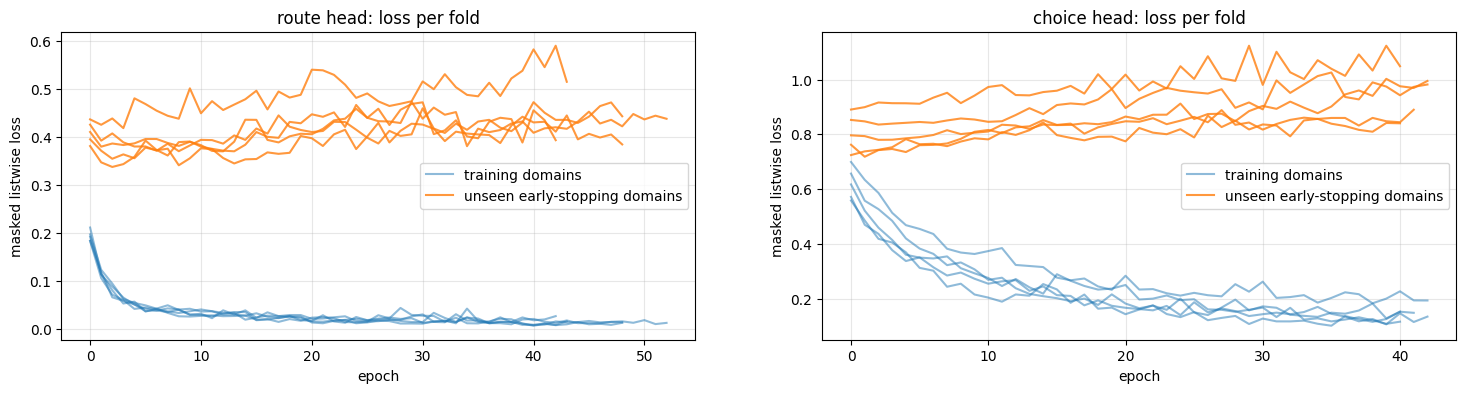

[16:04:59] final heads, epochs {'route': 9, 'choice': 2}, 18.5s | RAM 6.2 GB | GPU 4.2 GB
the decider's model-card example, asked to the choice head:
  Which team should handle this?     billing 0.79 | sales 0.13 | retail 0.09
  Does this convey urgency?          yes 0.44 | no 0.56
  How frustrated is the writer?      calm 0.05 | frustrated 0.81 | furious 0.14


In [31]:
# Cell 8 — Loss curves, the two final heads, and the router / ask functions

fig, axes = plt.subplots(1, len(GROUPS), figsize=(9 * len(GROUPS), 4), squeeze=False)
for ax, g in zip(axes[0], GROUPS):
    for f, hist in enumerate(results[g]["histories"]):
        ax.plot([h[0] for h in hist], color="tab:blue", alpha=0.5, label="training domains" if f == 0 else None)
        ax.plot([h[1] for h in hist], color="tab:orange", alpha=0.8, label="unseen early-stopping domains" if f == 0 else None)
    ax.set_xlabel("epoch"); ax.set_ylabel("masked listwise loss"); ax.set_title(f"{g} head: loss per fold")
    ax.legend(); ax.grid(alpha=0.3)
plt.show()


def train_final(g):
    """The head on ALL of its own questions, for the median best epoch of its folds, with its own statistics."""
    gd = GD[g]
    epochs = max(1, int(statistics.median(results[g]["best_epochs"])))
    X_all, stats = grid_features(gd)
    head, _, _ = train_head(X_all, listwise_loss(X_all, gd["labels"], gd["mask"]), torch.arange(gd["n"]), epochs=epochs)
    del X_all
    return {"head": head, "stats": tuple(s_.cpu() for s_ in stats), "epochs": epochs}


t0 = time.perf_counter()
FINAL = {g: train_final(g) for g in GROUPS}
head_train_time = time.perf_counter() - t0
log(f"final heads, epochs {({g: h['epochs'] for g, h in FINAL.items()})}, {head_train_time:.1f}s | {mem()}")


def question_probs(final, questions):
    """Many questions through one final head at once. A question is {messages, options: {name: description}, current?,
    question?}; its pairs go on the [questions, K_MAX] grid of training -> probabilities [Q, K_MAX] (padded slots 0)."""
    rows = [{"messages": q["messages"], "current": q.get("current"), "question": q.get("question", ROUTE_Q), "agent": n,
             "candidate": option_text(n, d)} for q in questions for n, d in q["options"].items()]
    qi = torch.tensor([i for i, q in enumerate(questions) for _ in q["options"]])
    slot = torch.tensor([k for q in questions for k in range(len(q["options"]))])
    cross, dual, is_current = raw_features(rows, save=False)
    X = torch.zeros(len(questions), K_MAX, 8 * H_ + 5, device=DEVICE)
    mask = torch.zeros(len(questions), K_MAX, dtype=torch.bool, device=DEVICE)
    with torch.no_grad():
        X[qi, slot] = matching_features(cross, dual, final["stats"], is_current).to(DEVICE)
        mask[qi, slot] = True
        return torch.softmax(masked_scores(final["head"], X, mask), dim=1).cpu()


def score_candidates(messages, agents, current=None):
    """The ROUTER (route head) for one conversation: log-probabilities over the agents."""
    return question_probs(FINAL["route"], [{"messages": messages, "options": agents, "current": current}])[0, :len(agents)].log()


def ask(messages, question, options, current=None):
    """A general question (choice head) -> {option: probability}; options: names or {name: description}."""
    opts = options if isinstance(options, dict) else {o: "" for o in options}
    p = question_probs(FINAL.get("choice", FINAL["route"]), [{"messages": messages, "options": opts, "current": current, "question": question}])
    return dict(zip(opts, p[0].tolist()))


demo = [{"role": "user", "content": "Help! My payouts have been failing for 3 days!"}]
print("the decider's model-card example, asked to the choice head:")
for q, opts in [("Which team should handle this?", ["billing", "sales", "retail"]), ("Does this convey urgency?", ["yes", "no"]),
                ("How frustrated is the writer?", ["calm", "frustrated", "furious"])]:
    print(f"  {q:34s} " + " | ".join(f"{k} {v:.2f}" for k, v in ask(demo, q, opts).items()))

---
# Routing

## Cell 9 — Routing one banking conversation

The five banking agents appear in no training data. Each is just a **name and a description**, read together with the conversation:

```text
history + current agent + Payments Agent        → encoder → head → score
history + current agent + Card Support Agent    → encoder → head → score
...                                                                          → softmax → chosen agent
```

Each candidate gets its own joint pass, so nothing can be shared between them: that's the price of letting the conversation and the description attend to each other. Payments and Card Support are a deliberate **close pair**: "my card payment failed" has words of both. Softmax turns the five scores into probabilities that sum to 1; only their differences matter.

**Expect.** The conversation (the user says "OK" right after a handoff to Payments), one row per agent, and the time of a live decision.

In [32]:
# Cell 9 — The five banking agents, and one live routing decision

AGENTS = {
    "Payments Agent": "Handles bank transfers, failed or pending payments, transaction status, payment charges and "
                      "duplicate charges, refunds for transactions, and settlement problems where money was sent but "
                      "not received. Does not handle card servicing such as blocking, replacing or activating cards.",
    "Card Support Agent": "Handles debit and credit card servicing: card activation, blocking and unblocking, lost or "
                          "stolen cards, card replacement and delivery, card limits, card PIN, card security and "
                          "compromised card details, and card-specific transactions.",
    "Investment Agent": "Handles mutual funds, SIPs, investments, portfolio allocation, investment transactions, "
                        "redemptions and investment planning.",
    "Insurance Agent": "Handles insurance policies, premiums, renewals, claims, policy expiry and policy servicing.",
    "General Customer Support Agent": "Handles general account questions, profile and contact details, issues that do "
                                      "not clearly belong to a specialist, and routing customers to the right agent.",
}
AGENT_NAMES = list(AGENTS)
CLOSE_PAIR = {"Payments Agent", "Card Support Agent"}

routing_example = next((ex for ex in banking_benchmark if ex["id"] == "011-e0"), banking_benchmark[0])   # handoff + "OK"
print("conversation:")
for m in routing_example["messages"]:
    print(f"  {m['role']:9s}: {m['content']}")
print(f"current agent: {routing_example['current_agent']}\n")

t0 = time.perf_counter()
scores = score_candidates(routing_example["messages"], AGENTS, routing_example["current_agent"])
live_latency = time.perf_counter() - t0
probs = torch.softmax(scores, dim=0)
assert torch.isclose(probs.sum(), torch.tensor(1.0))
assert torch.allclose(torch.softmax(scores + 7.0, dim=0), probs), "shift-invariant"

print(f"{'agent':32s} | {'tokens':>6} | {'log-prob':>8} | {'probability':>11}")
for k, name in enumerate(AGENT_NAMES):
    n_tok = len(ROUTER_ENC.tokenizer(option_text(name, AGENTS[name]), add_special_tokens=False)["input_ids"])
    print(f"{name:32s} | {n_tok:>6} | {scores[k].item():8.3f} | {probs[k].item():11.3f}"
          + ("  <== chosen" if k == int(probs.argmax()) else "") + ("  (correct)" if name == routing_example["target_agent"] else ""))
per_pass = timing["encoder_seconds"] / max(1, timing["encoder_passes"])
print(f"\nlive decision: {live_latency * 1000:.0f} ms on {DEVICE} | mean encoder pass during feature extraction {per_pass * 1000:.1f} ms")

conversation:
  user     : Transfer marked complete, but my friend still hasn't got the funds.
  assistant: This is probably a settlement delay.
  user     : Can you help?
  assistant: Please continue with the Payments Agent for transfer and settlement problems.
  user     : OK
current agent: General Customer Support Agent

agent                            | tokens | log-prob | probability
Payments Agent                   |     50 |   -0.006 |       0.994  <== chosen  (correct)
Card Support Agent               |     47 |   -5.930 |       0.003
Investment Agent                 |     26 |   -8.373 |       0.000
Insurance Agent                  |     20 |   -7.732 |       0.000
General Customer Support Agent   |     33 |   -6.011 |       0.002

live decision: 132 ms on cuda | mean encoder pass during feature extraction 17.9 ms


## Cell 10 — Banking: 225 test conversations

Every banking conversation is routed among the five agents and scored per category: obvious requests, the close pair (does the right agent beat its sibling?), handoffs and "OK" right after one, context-dependent last messages, and conversation length. The confusion matrix then shows *how* it fails: errors inside the Payments / Card block mean the boundary wasn't learned; errors into General mean uncertainty.

**Expect.** Run 17: 43 / 50 on the benchmark and 194 / 225 overall (the decider: 48 and 214).

[16:05:00] routing the banking test conversations
[16:05:04] cross features: 875 new encoder passes (nvidia/llama-nemotron-embed-1b-v2)
[16:05:16] cross features done: 875 passes in 12s
metric                                     |            benchmark |          all banking
overall                                    |     44 / 50  (88.0%) |    200 / 225 (88.9%)
obvious                                    |      9 / 10  (90.0%) |     43 / 45  (95.6%)
close pair: right agent beats its sibling  |     23 / 26  (88.5%) |    105 / 117 (89.7%)
close pair: 5-way                          |     22 / 26  (84.6%) |     97 / 117 (82.9%)
handoff                                    |      9 / 12  (75.0%) |     42 / 54  (77.8%)
OK after a handoff                         |      9 / 12  (75.0%) |     42 / 54  (77.8%)
context-dependent                          |     27 / 30  (90.0%) |    118 / 135 (87.4%)
short (1-3 messages)                       |     19 / 20  (95.0%) |     88 / 90  (97.8%)
medium (4-8 m

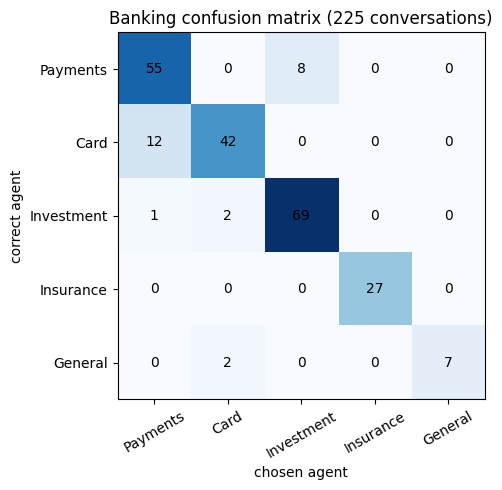

benchmark errors (6 of 50):
  005-e0  correct General    -> Card       | last user message: 'I want to change my registered phone number.'
  012-e1  correct Card       -> Payments   | last user message: 'ok'
  017-e1  correct Investment -> Payments   | last user message: 'no forget card, invest'
  023-e0  correct Payments   -> Investment | last user message: 'How do I get the money transferred into that account?'
  025-e0  correct Card       -> Payments   | last user message: 'OK'
  025-e1  correct Card       -> Payments   | last user message: 'ok'


In [33]:
# Cell 10 — Banking: routing per category, then the confusion matrix; a table helper for the test cells

def table(rows, key, cols, groups=None):
    """Print right / total per group (key(row) -> group) and for ALL rows; cols = {column: row -> True if right}."""
    groups = list(groups or sorted({key(r) for r in rows})) + ["ALL"]
    w = max(len(str(g_)) for g_ in groups)
    print(f"  {'':{w}s} | {'n':>4} | " + " | ".join(f"{c:>12s}" for c in cols))
    for g_ in groups:
        rs = [r for r in rows if g_ == "ALL" or key(r) == g_]
        if rs:
            print(f"  {g_:{w}s} | {len(rs):>4} | " + " | ".join(f"{sum(map(f_, rs)):>5} / {len(rs):<4}" for f_ in cols.values()))


def route_conversations(conversations):
    P = question_probs(FINAL["route"], [{"messages": ex["messages"], "current": ex["current_agent"], "options": AGENTS} for ex in conversations])
    return [{"ex": ex, "scores": p[:5], "pred": AGENT_NAMES[int(p.argmax())]} for ex, p in zip(conversations, P)]


def category_metrics(rows):
    def count(rs):
        return sum(r["pred"] == r["ex"]["target_agent"] for r in rs), len(rs)

    def tagged(tag):
        return [r for r in rows if tag in r["ex"]["tags"]]

    close = [r for r in rows if r["ex"]["target_agent"] in CLOSE_PAIR]
    beats = sum(bool(r["scores"][AGENT_NAMES.index(r["ex"]["target_agent"])]
                     > r["scores"][AGENT_NAMES.index(next(iter(CLOSE_PAIR - {r["ex"]["target_agent"]})))]) for r in close)
    return {"overall": count(rows), "obvious": count(tagged("obvious")), "close pair: right agent beats its sibling": (beats, len(close)),
            "close pair: 5-way": count(close), "handoff": count(tagged("handoff")), "OK after a handoff": count(tagged("ok_after_handoff")),
            "context-dependent": count(tagged("context")), "short (1-3 messages)": count(tagged("short")),
            "medium (4-8 messages)": count(tagged("medium")), "long (9-15 messages)": count(tagged("long"))}


def fmt(pc):
    return f"{pc[0]:>3} / {pc[1]:<3} ({pc[0] / pc[1]:5.1%})" if pc[1] else "n/a"


log("routing the banking test conversations")
eval_results = route_conversations(banking_benchmark)
all_results = eval_results + route_conversations(banking_extended)
eval_metrics, all_metrics = category_metrics(eval_results), category_metrics(all_results)
print(f"{'metric':42s} | {'benchmark':>20} | {'all banking':>20}")
for k in eval_metrics:
    print(f"{k:42s} | {fmt(eval_metrics[k]):>20} | {fmt(all_metrics[k]):>20}")

short_names = {"Payments Agent": "Payments", "Card Support Agent": "Card", "Investment Agent": "Investment",
               "Insurance Agent": "Insurance", "General Customer Support Agent": "General"}
true_i = torch.tensor([AGENT_NAMES.index(r["ex"]["target_agent"]) for r in all_results])
pred_i = torch.tensor([AGENT_NAMES.index(r["pred"]) for r in all_results])
confusion = torch.bincount(true_i * 5 + pred_i, minlength=25).view(5, 5)          # rows correct, columns chosen
labels5 = [short_names[n] for n in AGENT_NAMES]
fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(confusion.numpy(), cmap="Blues")
for i in range(5):
    for j in range(5):
        ax.text(j, i, int(confusion[i, j]), ha="center", va="center")
ax.set_xticks(range(5), labels5, rotation=30); ax.set_yticks(range(5), labels5)
ax.set_xlabel("chosen agent"); ax.set_ylabel("correct agent"); ax.set_title(f"Banking confusion matrix ({len(all_results)} conversations)")
plt.tight_layout(); plt.show()

errors = [r for r in eval_results if r["pred"] != r["ex"]["target_agent"]]
print(f"benchmark errors ({len(errors)} of {len(eval_results)}):")
for r in errors:
    print(f"  {r['ex']['id']:7s} correct {short_names[r['ex']['target_agent']]:10s} -> {short_names[r['pred']]:10s} "
          f"| last user message: {r['ex']['messages'][-1]['content']!r}")

## Cell 11 — E11: first messages only

The core skill with nothing around it: **one message, no history, no current agent**, 5 agents per company. 100 messages from 10 companies that appear nowhere else, with deliberately close pairs (Bin Collections vs Garden Waste), written free-form and never used in training. Message types: clear, short (1–4 words), indirect (no keyword), close (between two similar agents) and noisy (typos).

**Expect.** Top-1 and top-2 per type and per company, and every mistake. Run 17: 94 / 100 top-1, 97 top-2 (the decider: 96).

In [34]:
# Cell 11 — E11: 100 first messages, each routed among its company's 5 agents (one batch)

log(f"E11: {len(ft_msgs)} first messages, {len(ft_companies)} companies x 5 agents")
P = question_probs(FINAL["route"], [{"messages": [{"role": "user", "content": m["message"]}], "options": ft_companies[m["company"]]}
                                    for m in ft_msgs])
ft_rows = []
for m, p_ in zip(ft_msgs, P):
    names, top2 = list(ft_companies[m["company"]]), p_.topk(2).indices.tolist()
    ft_rows.append({**m, "router": names[top2[0]], "router_top2": [names[i] for i in top2], "p_router": p_.max().item()})

top1 = {"top-1": lambda r: r["router"] == r["target_agent"]}
table(ft_rows, lambda r: r["type"], {**top1, "top-2": lambda r: r["target_agent"] in r["router_top2"]},
      ["clear", "short", "indirect", "close", "noisy"])
print("\nper company:")
table(ft_rows, lambda r: r["company"], top1, list(ft_companies))
print("\nmistakes:")
for r in [r for r in ft_rows if r["router"] != r["target_agent"]]:
    msg = r["message"] if len(r["message"]) <= 58 else r["message"][:55] + "..."
    print(f"  {r['type']:8s} | {msg:58s} | expected {r['target_agent'].replace(' Agent', ''):26s} | "
          f"got {r['router'].replace(' Agent', '')} ({r['p_router']:.2f})")

[16:05:18] E11: 100 first messages, 10 companies x 5 agents
[16:05:18] cross features: 500 new encoder passes (nvidia/llama-nemotron-embed-1b-v2)
[16:05:22] cross features done: 500 passes in 3s
           |    n |        top-1 |        top-2
  clear    |   31 |    29 / 31   |    30 / 31  
  short    |   17 |    17 / 17   |    17 / 17  
  indirect |   17 |    16 / 17   |    16 / 17  
  close    |   20 |    17 / 20   |    19 / 20  
  noisy    |   15 |    15 / 15   |    15 / 15  
  ALL      |  100 |    94 / 100  |    97 / 100 

per company:
                                 |    n |        top-1
  online grocery                 |   10 |    10 / 10  
  smartwatch maker               |   10 |    10 / 10  
  council waste services         |   10 |     9 / 10  
  online marketplace for sellers |   10 |    10 / 10  
  home appliance maker           |   10 |     9 / 10  
  cinema chain                   |   10 |     8 / 10  
  bike share scheme              |   10 |     9 / 10  
  accounting so

## Cell 12 — E10: whole conversations, routed live

35 free-form conversations from 13 companies that appear nowhere in training (a pharmacy, a cruise line, a driving school, …), 3 broad agents each, **193 user turns**. Every turn is routed with the history so far, and the router's **own previous pick** is its current agent, as in deployment, so a mistake can carry over.

| Turn type | Meaning |
|---|---|
| start | the first message |
| answer · follow · aspect | a short answer to the agent's question · a follow-up · another aspect, same agent |
| closing · also_stay | "ok cheers" · "Also …" that stays with the agent |
| switch · short_switch · return | a clear switch · a switch in a few words · back to an earlier topic |
| handoff_ok · branch | "ok" after a handoff · the same words, a different agent depending on the history |

**Expect.** Pass / total per turn type and the first mistakes. Run 17: 158 / 193 (the decider: 151 with the full history).

In [35]:
# Cell 12 — E10: every user turn routed live; the router's own previous pick is the current agent

def pick_router(messages, agents, current):
    return list(agents)[int(torch.argmax(score_candidates(messages, agents, current)))]


log(f"E10: {len(real_convs)} conversations, {sum(len(c['user_turns']) for c in real_convs)} user turns")
e10_rows = []
for k, conv in enumerate(real_convs):
    current = None
    for u in conv["user_turns"]:
        prefix = conv["messages"][:u["message_index"] + 1]
        current = pick_router(prefix, conv["agents"], current)
        e10_rows.append({"id": conv["id"], "company": conv["company"], "type": u["turn_type"], "expected": u["expected_agent"],
                         "message": prefix[-1]["content"], "router": current})
    if (k + 1) % 10 == 0:
        log(f"  E10 {k + 1}/{len(real_convs)} conversations")

TURN_TYPES = ["start", "answer", "follow", "aspect", "closing", "also_stay", "switch", "short_switch", "return", "handoff_ok", "branch"]
print(f"E10 live | router encoder: {ROUTER_ENCODER}")
table(e10_rows, lambda r: r["type"], {"router": lambda r: r["router"] == r["expected"]}, TURN_TYPES)

print("\nfirst 15 mistakes:")
for r in [r for r in e10_rows if r["router"] != r["expected"]][:15]:
    msg = r["message"] if len(r["message"]) <= 50 else r["message"][:47] + "..."
    print(f"  {r['id']:9s} {r['type']:12s} | {msg:50s} | expected {r['expected'].replace(' Agent', ''):22s} | "
          f"got {r['router'].replace(' Agent', '')}")

[16:05:23] E10: 35 conversations, 193 user turns
[16:05:28]   E10 10/35 conversations
[16:05:32]   E10 20/35 conversations
[16:05:36]   E10 30/35 conversations
E10 live | router encoder: nemotron-1b
               |    n |       router
  start        |   35 |    32 / 35  
  answer       |   51 |    41 / 51  
  follow       |   21 |    16 / 21  
  aspect       |    7 |     6 / 7   
  closing      |   15 |    10 / 15  
  also_stay    |    4 |     4 / 4   
  switch       |   42 |    29 / 42  
  short_switch |    6 |     6 / 6   
  return       |    7 |     5 / 7   
  handoff_ok   |    2 |     0 / 2   
  branch       |    3 |     2 / 3   
  ALL          |  193 |   151 / 193 

first 15 mistakes:
  pharm-1   start        | Hi, I need a refill on my blood pressure tablets.  | expected Repeat Prescriptions   | got Pharmacist Advice
  pharm-1   answer       | yes that one                                       | expected Repeat Prescriptions   | got Pharmacist Advice
  pharm-2   switch       | A

---
# The gate

## Cell 13 — A simpler question: has the topic changed?

Most routing mistakes were short replies ("Sunday", "ok thanks") sent back to the conversation's *first* topic. So before choosing among agents, ask one yes / no question about the **last user message**: does it move the conversation to a **different topic** (Y), or continue the current one (N)? It needs no candidates. The training conversations carry this label:
- **N:** follow-ups, short answers to the agent's question ("Sunday", "12 Harbour Road"), closings, "ok" after a handoff, "Also …" that stays on topic.
- **Y:** topic changes, short switches ("and the bill?"), returns to an earlier topic, "forget the X, I want Y".

There are many short Y examples, or the detector would learn "short means N".

**Expect.** The Y / N counts, how many last messages are short, and one example of each kind.

In [36]:
# Cell 13 — Context-change labels: does the LAST user message move the conversation to a different topic? (Y / N)

cc_examples = [ex for ex in generic_conversations if ex["context_change"] is not None]   # needs a previous turn
cc_labels = torch.tensor([float(ex["context_change"]) for ex in cc_examples])
cc_fold = torch.tensor([FOLD_OF["route"][ex["domain"]] for ex in cc_examples])


def is_short(ex):
    return len(ex["messages"][-1]["content"].split()) <= 3


short_ex = [ex for ex in cc_examples if is_short(ex)]
print(f"{len(cc_examples)} training conversations with a previous turn: {int(cc_labels.sum())} Y (topic changed) | "
      f"{len(cc_examples) - int(cc_labels.sum())} N")
print(f"short last messages (<= 3 words): {len(short_ex)} | Y {sum(ex['context_change'] for ex in short_ex)} | "
      f"N {sum(not ex['context_change'] for ex in short_ex)}")

for tag in ["short_answer", "closing", "short_switch", "topic_change", "ok_after_handoff", "stay_prefix", "return_again", "after_general"]:
    ex = next((e for e in cc_examples if tag in e["tags"] and (tag != "short_answer" or "closing" not in e["tags"])), None)
    if ex is None:
        continue
    print(f"\n[{tag}]  current agent: {ex['current_agent']}  ->  topic changed: {'Y' if ex['context_change'] else 'N'}")
    for m in ex["messages"][-3:]:
        print(f"   {m['role']:9s}: {m['content']}")

5948 training conversations with a previous turn: 2819 Y (topic changed) | 3129 N
short last messages (<= 3 words): 2916 | Y 601 | N 2315

[short_answer]  current agent: Password & Access Agent  ->  topic changed: N
   user     : I need admin rihgts on the CRM.
   assistant: Which device are you using?
   user     : PS5

[closing]  current agent: Password & Access Agent  ->  topic changed: N
   user     : My login keeps getting rejected.
   assistant: I've noted that.
   user     : got it

[short_switch]  current agent: Network & VPN Agent  ->  topic changed: Y
   user     : The VPN keeps disconnecting.
   assistant: Here is what I found.
   user     : printer please

[topic_change]  current agent: Software Installation Agent  ->  topic changed: Y
   user     : The PDF editor shows a license error.
   assistant: Sure, let me look into that.
   user     : Different thing: my login keeps getting rejected.

[ok_after_handoff]  current agent: General IT Support Agent  ->  topic changed: N


## Cell 14 — The detector, scored on domains it never saw

One pass of the **detector's encoder** (ModernBERT) over `history [SEP] current agent: X`. Three spans are mean-pooled: the **last user message** (its tokens have read the history), **everything before it**, and the **assistant message just before it** (often the question a short answer refers to). After standardizing: the three vectors, plus products and |differences| of the last message against the other two, 7H features. The head is the same MLP-256 with a class-balanced loss, on the router's leave-domains-out folds.

**Expect.** Held-out "Y found" and "N kept", for all messages and for short ones (≤ 3 words), the hard case.

In [37]:
# Cell 14a — Detector features: one pass over (history [SEP] current agent), three spans pooled

CC_CACHE = CACHE_DIR / f"context_{DETECTOR_ENC.tag}.pt"
cc_cache = torch.load(CC_CACHE) if CC_CACHE.exists() else {}


def context_features(examples):
    """-> [N, 3, H]: means of the last user message, everything before it, and the assistant message just before it,
    all from ONE pass of the detector's encoder, so the last message's tokens have read the history."""
    built = [build_text(ex["messages"], ex["current_agent"], None, DETECTOR_ENC.query, enc=DETECTOR_ENC) for ex in examples]
    ranges = [[sp["messages"][-1], (sp["messages"][0][0], sp["messages"][-2][1]), sp["messages"][-2]] for _, sp in built]
    return span_means([t for t, _ in built], ranges, cc_cache, CC_CACHE, "context features", enc=DETECTOR_ENC)


def context_matching(feats, stats):
    """Standardize; the last message, history and previous assistant message, and how the last message compares with
    the other two (products, |differences|) -> [N, 7H]."""
    z = (feats - stats[0]) / stats[1]
    l, h, a = z[:, 0], z[:, 1], z[:, 2]
    return torch.cat([l, h, a, l * h, (l - h).abs(), l * a, (l - a).abs()], dim=1)


cc_feats = context_features(cc_examples)
print(f"detector features {tuple(cc_feats.shape)} (conversations, [last message, history, previous assistant message], H)")

detector features (5948, 3, 1024) (conversations, [last message, history, previous assistant message], H)


In [38]:
# Cell 14b — Train the Y / N detector on 3 folds, early-stop on the 4th, score the held-out 5th

def balanced_bce(X, y, idx_tr):
    """Binary cross-entropy with Y and N counting equally (positives weighted by #N / #Y of the training rows)."""
    y_tr = y[idx_tr.to(y.device)]
    pos_weight = (1 - y_tr).sum() / y_tr.sum().clamp(min=1)
    return lambda head, b: F.binary_cross_entropy_with_logits(head(X[b]).squeeze(-1), y[b], pos_weight=pos_weight)


def yn_counts(pred, y):
    """-> Y / N counts: tp (said Y, was Y), fn (said N, was Y), tn, fp."""
    pred, y = pred.bool(), y.bool()
    return Counter({"tp": int((pred & y).sum()), "fn": int((~pred & y).sum()), "tn": int((~pred & ~y).sum()), "fp": int((pred & ~y).sum())})


def fmt_cc(c):
    yes, no = c["tp"] + c["fn"], c["tn"] + c["fp"]
    return f"{c['tp'] + c['tn']:>5} / {yes + no:<5} correct | Y: {c['tp']:>4}/{yes:<4} found | N: {c['tn']:>4}/{no:<4} kept"


short_mask = torch.tensor([is_short(ex) for ex in cc_examples])
cc_all, cc_short, cc_best_epochs, t0 = Counter(), Counter(), [], time.perf_counter()
cc_y = cc_labels.to(DEVICE)
for f in range(N_FOLDS):
    te, va = cc_fold == f, cc_fold == (f + 1) % N_FOLDS
    tr = ~(te | va)
    stats = (cc_feats[tr].mean(0, keepdim=True), cc_feats[tr].std(0, keepdim=True) + 1e-6)
    X = context_matching(cc_feats, stats).to(DEVICE)
    idx_tr = tr.nonzero().flatten()
    head, best_epoch, _ = train_head(X, balanced_bce(X, cc_y, idx_tr), idx_tr, va.nonzero().flatten())
    with torch.no_grad():
        pred = (head(X[te.to(DEVICE)]).squeeze(-1) > 0).cpu()
    cc_all.update(yn_counts(pred, cc_labels[te]))
    cc_short.update(yn_counts(pred[short_mask[te]], cc_labels[te][short_mask[te]]))
    cc_best_epochs.append(best_epoch)
    log(f"  detector fold {f} | best epoch {best_epoch:3d} | held-out: {fmt_cc(yn_counts(pred, cc_labels[te]))}")
    del X, head
print(f"\nheld-out domains, {time.perf_counter() - t0:.0f}s | best epochs {cc_best_epochs}")
print(f"  all messages   : {fmt_cc(cc_all)}")
print(f"  short (<= 3 w) : {fmt_cc(cc_short)}")

[16:05:53]   detector fold 0 | best epoch  85 | held-out:   743 / 773   correct | Y:  357/371  found | N:  386/402  kept
[16:06:06]   detector fold 1 | best epoch 104 | held-out:  1444 / 1490  correct | Y:  683/701  found | N:  761/789  kept
[16:06:20]   detector fold 2 | best epoch 103 | held-out:  1248 / 1292  correct | Y:  596/615  found | N:  652/677  kept
[16:06:31]   detector fold 3 | best epoch  69 | held-out:  1063 / 1108  correct | Y:  496/518  found | N:  567/590  kept
[16:06:48]   detector fold 4 | best epoch 131 | held-out:  1252 / 1285  correct | Y:  607/614  found | N:  645/671  kept

held-out domains, 68s | best epochs [85, 104, 103, 69, 131]
  all messages   :  5750 / 5948  correct | Y: 2739/2819 found | N: 3011/3129 kept
  short (<= 3 w) :  2887 / 2916  correct | Y:  582/601  found | N: 2305/2315 kept


## Cell 15 — The final detector, tested on E10

The detector trains on all training conversations for the median best epoch of its folds. Then it is tested on every E10 turn after the first: a turn is **Y** when its expected agent differs from the previous turn's, and the current agent is the previous turn's *correct* agent, so this measures the detector alone, without the router's mistakes. E10 is never used to train it.

**Expect.** Y found and N kept on E10 next to the held-out score, and the result per turn type.

In [39]:
# Cell 15 — Final detector on all training conversations; tested on E10's labelled turns

CC_STATS = (cc_feats.mean(0, keepdim=True), cc_feats.std(0, keepdim=True) + 1e-6)
cc_epochs = max(1, int(statistics.median(cc_best_epochs)))
X_all, idx_all = context_matching(cc_feats, CC_STATS).to(DEVICE), torch.arange(len(cc_labels))
cc_head, _, _ = train_head(X_all, balanced_bce(X_all, cc_y, idx_all), idx_all, epochs=cc_epochs)
del X_all
log(f"final context-change detector: {cc_epochs} epochs, {len(cc_examples)} training conversations")


def p_change(messages, current):
    """Probability that the last user message changes the topic, given the history and the agent holding it."""
    feats = context_features([{"messages": messages, "current_agent": current}])
    with torch.no_grad():
        return torch.sigmoid(cc_head(context_matching(feats, CC_STATS).to(DEVICE))).item()


e10_cc = []                                   # every E10 turn after the first: truth Y = the expected agent changed
for conv in real_convs:
    prev = None
    for u in conv["user_turns"]:
        if prev is not None:
            p = p_change(conv["messages"][:u["message_index"] + 1], prev)
            e10_cc.append({"type": u["turn_type"], "truth": u["expected_agent"] != prev, "said": p > 0.5})
        prev = u["expected_agent"]
c_e10 = yn_counts(torch.tensor([r["said"] for r in e10_cc]), torch.tensor([r["truth"] for r in e10_cc]))
print(f"held-out training domains     : {fmt_cc(cc_all)}")
print(f"E10, {len(e10_cc):3d} turns after the first : {fmt_cc(c_e10)}")
print("\nE10 per turn type:")
table(e10_cc, lambda r: r["type"], {"detector right": lambda r: r["said"] == r["truth"], "truth Y": lambda r: r["truth"]}, TURN_TYPES)

[16:07:05] final context-change detector: 103 epochs, 5948 training conversations
held-out training domains     :  5750 / 5948  correct | Y: 2739/2819 found | N: 3011/3129 kept
E10, 158 turns after the first :   131 / 158   correct | Y:   55/59   found | N:   76/99   kept

E10 per turn type:
               |    n | detector right |      truth Y
  answer       |   51 |    50 / 51   |     0 / 51  
  follow       |   21 |    10 / 21   |     0 / 21  
  aspect       |    7 |     0 / 7    |     0 / 7   
  closing      |   15 |    15 / 15   |     0 / 15  
  also_stay    |    4 |     1 / 4    |     0 / 4   
  switch       |   42 |    41 / 42   |    42 / 42  
  short_switch |    6 |     5 / 6    |     6 / 6   
  return       |    7 |     7 / 7    |     7 / 7   
  handoff_ok   |    2 |     0 / 2    |     2 / 2   
  branch       |    3 |     2 / 3    |     2 / 3   
  ALL          |  158 |   131 / 158  |    59 / 158 


## Cell 16 — The gate: "confident stay"

The detector is very reliable at its low end, so use it only there:

```text
p = p(topic changed | conversation, current agent)
p < τ  (sure nothing changed)  → keep the current agent
otherwise                      → the router picks among all agents
```

The gate can only keep an agent, never exclude one. **τ is chosen honestly:** E10's 13 companies are split into 7 **dev** companies, where τ ∈ {0.02, 0.05, 0.1, 0.2, 0.3} is swept (ties go to the smaller τ), and 6 **test** companies (83 turns), where it is reported next to the router alone.

**Expect.** The dev sweep, and the test table per turn type. Run 17: 72 / 83 with the gate against 69 for the router alone (the decider: 62).

In [40]:
# Cell 16 — The confident-stay gate on E10: τ chosen on 7 dev companies, reported on the other 6

companies = sorted({c["company"] for c in real_convs})
DEV_COMPANIES = set(companies[::2])
TEST_COMPANIES = set(companies) - DEV_COMPANIES
dev_convs = [c for c in real_convs if c["company"] in DEV_COMPANIES]
test_convs = [c for c in real_convs if c["company"] in TEST_COMPANIES]
TAUS = [0.02, 0.05, 0.1, 0.2, 0.3]
_memo = {}


def memo(key, fn):
    """The same (turn, current agent) always gives the same answer: compute it once across all τ."""
    if key not in _memo:
        _memo[key] = fn()
    return _memo[key]


def run_live(convs, tau=None):
    """Route every turn live, the gate's own previous pick holding the conversation: p < tau -> stay; else the router."""
    rows = []
    for conv in convs:
        cur = None
        for k, u in enumerate(conv["user_turns"]):
            prefix = conv["messages"][:u["message_index"] + 1]
            p = memo(("p", conv["id"], k, cur), lambda: p_change(prefix, cur)) if tau is not None and cur in conv["agents"] else None
            action = "stay" if p is not None and p < tau else "route"
            if action == "route":
                cur = memo(("r", conv["id"], k, cur), lambda: pick_router(prefix, conv["agents"], cur))
            rows.append({"type": u["turn_type"], "action": action, "ok": cur == u["expected_agent"]})
    return rows


def n_ok(rows):
    return sum(r["ok"] for r in rows)


log(f"gate: dev {len(DEV_COMPANIES)} companies, test {len(TEST_COMPANIES)} companies")
dev_scores = [n_ok(run_live(dev_convs, t)) for t in TAUS]
TAU = TAUS[max(range(len(TAUS)), key=lambda i: (dev_scores[i], -i))]
print(f"DEV ({', '.join(sorted(DEV_COMPANIES))})")
print(f"  router alone {n_ok(run_live(dev_convs))} / {sum(len(c['user_turns']) for c in dev_convs)} | gate: "
      + " | ".join(f"τ {t}: {s_}" for t, s_ in zip(TAUS, dev_scores)) + f"  -> τ = {TAU}")

GATE = f"gate, τ {TAU}"
test_rows = {"router alone": run_live(test_convs), GATE: run_live(test_convs, TAU)}
print(f"\nTEST ({', '.join(sorted(TEST_COMPANIES))}), τ chosen on dev only")
both = [{"type": a["type"], "router": a["ok"], "gate": b["ok"]} for a, b in zip(*test_rows.values())]
table(both, lambda r: r["type"], {"router alone": lambda r: r["router"], GATE: lambda r: r["gate"]}, TURN_TYPES)
stays = [r for r in test_rows[GATE] if r["action"] == "stay"]
print(f"\nthe gate kept the current agent on {len(stays)} test turns; {n_ok(stays)} of them were right")

[16:07:11] gate: dev 7 companies, test 6 companies
DEV (car dealership, dating app, electronics repair shop, parking operator, pharmacy, ride-hailing app, water utility)
  router alone 83 / 110 | gate: τ 0.02: 87 | τ 0.05: 87 | τ 0.1: 87 | τ 0.2: 86 | τ 0.3: 86  -> τ = 0.02

TEST (cruise line, driving school, games console company, pet food subscription, photo printing service, solar installer), τ chosen on dev only
               |    n | router alone | gate, τ 0.02
  start        |   15 |    15 / 15   |    15 / 15  
  answer       |   22 |    18 / 22   |    19 / 22  
  follow       |    9 |     8 / 9    |     8 / 9   
  aspect       |    1 |     1 / 1    |     1 / 1   
  closing      |    5 |     4 / 5    |     5 / 5   
  also_stay    |    3 |     3 / 3    |     3 / 3   
  switch       |   20 |    12 / 20   |    12 / 20  
  short_switch |    4 |     4 / 4    |     4 / 4   
  return       |    2 |     2 / 2    |     2 / 2   
  branch       |    2 |     1 / 2    |     1 / 2   
  ALL   

---
# Questions

## Cell 17 — E12: grounded choice questions

Can the same frozen features answer **general questions about a text**? E12 has 170 items written for this test and never used in training; every answer can be read from the text. Three types, the Strands decider's three primitives:

| Type | Items | Example: "Help! My payouts have been failing for 3 days!" |
|---|---|---|
| yes / no | 58 | Does this convey urgency? → yes |
| choice | 59 | Which team should handle this? billing / sales / retail → billing |
| score | 53 | How frustrated is the writer? calm / frustrated / furious → frustrated |

Eleven texts are asked several different questions (25 items), which checks that the model reads the **question**, not only the text. The choice head answers; it was trained only on questions about other texts.

**Expect.** Pass / total per type and category, the score errors in levels, the question groups and the mistakes. Run 17: 114 / 170 (the decider: 160). All 170 questions are scored in one batch, so the time per question is throughput, not one question's latency.

In [41]:
# Cell 17 — E12: 170 grounded questions asked to the choice head (one batch)

t0 = time.perf_counter()
P = question_probs(FINAL.get("choice", FINAL["route"]), [{"messages": [{"role": "user", "content": it["state"]}], "question": it["question"],
                                                          "options": {o: "" for o in it["options"]}} for it in e12_items])
e12_ms = (time.perf_counter() - t0) * 1000 / len(e12_items)
log(f"E12: {len(e12_items)} questions, {e12_ms:.0f} ms per question (batched)")
level = torch.arange(K_MAX, dtype=torch.float)
e12_rows = []
for it, p in zip(e12_items, P):
    top = int(p.argmax())
    row = {**it, "probs": p[:len(it["options"])].tolist(), "pick": it["options"][top], "ok": it["options"][top] == it["answer"]}
    if it["type"] == "score":
        row["expected_level"], row["level_error"] = float((p * level).sum()), abs(top - it["answer_index"])
    e12_rows.append(row)

right = {"right": lambda r: r["ok"]}
table(e12_rows, lambda r: r["type"], right, ["noul", "choice", "score"])
sc = [r for r in e12_rows if r["type"] == "score"]
if sc:
    print(f"score: exact {sum(r['level_error'] == 0 for r in sc)} / {len(sc)} | within 1 level {sum(r['level_error'] <= 1 for r in sc)} | "
          f"mean |expected - true| {sum(abs(r['expected_level'] - r['answer_index']) for r in sc) / len(sc):.2f} levels")
yes_rows = [r for r in e12_rows if r["type"] == "noul"]
print(f"yes / no: answered yes {sum(r['pick'] == 'yes' for r in yes_rows)} of {len(yes_rows)} (truth: {sum(r['answer'] == 'yes' for r in yes_rows)})")
print("\nper category:")
table(e12_rows, lambda r: r["category"], right)

groups = {}
for r in e12_rows:
    if "pair" in r:
        groups.setdefault(r["pair"], []).append(r)
print(f"\nquestion groups (same text, different questions): all right in {sum(all(r['ok'] for r in g) for g in groups.values())} of {len(groups)}")
for pid, g in groups.items():
    print(f"  {pid}: " + " | ".join(f"{r['question'][:34]} -> {r['pick']}{'' if r['ok'] else ' x'}" for r in g))

print("\nmistakes:")
for r in [r for r in e12_rows if not r["ok"]]:
    s_ = r["state"] if len(r["state"]) <= 46 else r["state"][:43] + "..."
    print(f"  {r['id']} {r['type']:6s} | {s_:46s} | {r['question'][:38]:38s} | expected {r['answer']:14s} | got {r['pick']} ({max(r['probs']):.2f})")

[16:07:17] E12: 170 questions, 19 ms per question (batched)
         |    n |        right
  noul   |   58 |    33 / 58  
  choice |   59 |    40 / 59  
  score  |   53 |    35 / 53  
  ALL    |  170 |   108 / 170 
score: exact 35 / 53 | within 1 level 50 | mean |expected - true| 0.53 levels
yes / no: answered yes 25 of 58 (truth: 30)

per category:
           |    n |        right
  compare  |   12 |     4 / 12  
  detail   |   38 |    22 / 38  
  fact     |   37 |    24 / 37  
  intent   |   22 |    13 / 22  
  language |    2 |     1 / 2   
  routing  |   14 |    11 / 14  
  tone     |   28 |    20 / 28  
  topic    |    4 |     4 / 4   
  urgency  |   13 |     9 / 13  
  ALL      |  170 |   108 / 170 

question groups (same text, different questions): all right in 3 of 11
  p01: Does this convey urgency? -> no x | Which team should handle this? -> billing | Which topic is this about? -> payments | How frustrated is the writer? -> frustrated | How urgent is this? -> medium x
  p02: 

---
# Results

## Cell 18 — Summary

Every number is correct / total, on companies and agents the router never saw in training, next to run 17 (the ledger) and the 2B Strands decider.

In [42]:
# Cell 18 — All results in one table

summary = [
    ("routing, held-out training domains", lodo_best, "5960 / 6850", None),
    ("banking benchmark", eval_metrics["overall"], "43 / 50", "48 / 50"),
    ("banking, all", all_metrics["overall"], "194 / 225", "214 / 225"),
    ("E11 first messages, top-1", (sum(r["router"] == r["target_agent"] for r in ft_rows), len(ft_rows)), "94 / 100", "96 / 100"),
    ("E10 all turns, router alone", (sum(r["router"] == r["expected"] for r in e10_rows), len(e10_rows)), "158 / 193", "151 / 193"),
    ("E10 test companies, router alone", (n_ok(test_rows["router alone"]), len(test_rows["router alone"])), "69 / 83", "62 / 83"),
    (f"E10 test companies, {GATE}", (n_ok(test_rows[GATE]), len(test_rows[GATE])), "72 / 83", None),
    ("E12 grounded questions (choice head)", (sum(r["ok"] for r in e12_rows), len(e12_rows)), "114 / 170", "160 / 170"),
]
print(f"{'test':40s} | {'this run':>13} | {'run 17':>11} | {'decider 2B':>11}")
print("-" * 84)
for name, (ok_, n), r17, dec in summary:
    print(f"{name:40s} | {ok_:>6} / {n:<4} | {r17:>11} | {dec or '—':>11}")
print(f"\nrouter {ROUTER_ENCODER}, detector {DETECTOR_ENCODER} | features {feature_time:.0f}s, folds {lodo_time:.0f}s, "
      f"final heads {head_train_time:.1f}s | {mem()}")

test                                     |      this run |      run 17 |  decider 2B
------------------------------------------------------------------------------------
routing, held-out training domains       |   5955 / 6850 | 5960 / 6850 |           —
banking benchmark                        |     44 / 50   |     43 / 50 |     48 / 50
banking, all                             |    200 / 225  |   194 / 225 |   214 / 225
E11 first messages, top-1                |     94 / 100  |    94 / 100 |    96 / 100
E10 all turns, router alone              |    151 / 193  |   158 / 193 |   151 / 193
E10 test companies, router alone         |     68 / 83   |     69 / 83 |     62 / 83
E10 test companies, gate, τ 0.02         |     70 / 83   |     72 / 83 |           —
E12 grounded questions (choice head)     |    108 / 170  |   114 / 170 |   160 / 170

router nemotron-1b, detector modernbert | features 6s, folds 225s, final heads 18.5s | RAM 6.1 GB | GPU 4.2 GB


---
## What we tried and dropped

Over 17 runs this notebook grew one idea at a time, and most ideas lost. The rule we used to decide, from run 12 on: tune every option on the 7 **dev** companies of the realistic test set (E10) and judge it on the 6 **test** companies (83 turns) it never saw. A component had to beat the simpler alternative by **at least 2 of those 83 turns** to stay; on a tie, the simpler or cheaper option won. Every number below is correct / total, from the run named in brackets. The full entries are in `experiments/modernbert_router_ledger.md`. The code of each dropped idea is kept in git history at the commit of its run.

### Router design

| Idea | What it did | Result | Why it was dropped |
|---|---|---|---|
| **PCA on the features** (run 3) | Reduce the features to 256 or 64 dimensions before the head; an 18-config grid per run | The winner used PCA 256; without PCA the heads overfit in 1–5 epochs | Removed after run 3 (a project decision, to keep the features whole and the grid small); not re-tested |
| **"Router x2"** (run 4) | Repeat the last user message in the input | E5: 29 vs 35 / 40 for the plain router | Hurt |
| **Dual-only and cross-only heads** (runs 1–11) | Score from the standalone embeddings only, or from the joint pass only | Held-out (run 11): dual 4,349, cross 5,280, combined **5,722** of 6,658. Cross-only was +4 on E10 in run 10 but −4 in run 11 | The combined head (both passes + similarities) was better or equal wherever results were stable |
| **Layer mix** (run 8) | Mean of the last 4 layers instead of the last layer | Worse than "last" for every feature set and head, by 1–2 points | Lost everywhere |
| **Per-run head selection** (runs 1–11) | Each run chose among MLP-64, MLP-256 and a residual head | Differences < 1% held-out, but in run 11 the selection switched heads at the same time as the data changed, so we couldn't tell which caused the result | Heads are fixed since run 12: router MLP-256, detector MLP-256 |
| **Choosing on generic held-out data** (run 8) | Pick models and weights by leave-domains-out accuracy on the template data | The winning head scored +57 there but went down on banking and realistic conversations; soft fusion added +423 there but lost 13 on banking | The template data rewards cues that real conversations don't have. That's why dev / test companies from the realistic set decide from run 9 on |

### Combining the router with a yes / no detector

| Idea | What it did | Result | Why it was dropped |
|---|---|---|---|
| **Agent-switch detector** (run 6) | A second yes / no model: "should a different agent answer?" | As the gate's detector: 73 vs **74** / 83 for the context-change detector (run 10); kept only 5 of 27 "stay" cases on banking | Never better than the context-change detector, doubled the training, and partly repeated the router's job |
| **Hard cascade** (run 6) | The detector decides stay / switch; on "switch" the current agent is excluded | Below the router alone everywhere: realistic 30 vs **34** / 40, banking 143 vs **176** / 225; E10 117 vs **154** / 193 (run 10) | A wrong "switch" became a guaranteed routing error, and errors carried forward live ("ok thanks" then stayed with the wrong agent) |
| **Soft fusion** (runs 8–11) | Router probabilities + w × detector evidence | Run 9: realistic +3, E10 +1, banking −10 | Mixed across test sets; the confident-stay gate does the useful part more simply |
| **Q-K-V attention head** (runs 7, 13) | A learned attention layer: the current message's tokens (Q) attend to the history (K, V) | Run 7 looked better out of domain, but run 8 didn't confirm it. Run 13 rewrite, current message encoded jointly or alone: 70 / 70 / 70 in the gate, held-out 5,677 vs **5,728** for pooled | The attention weights stayed almost uniform (≈ 1 / number of history tokens, on function words): pooling with extra parameters, and 17 minutes more per run |
| **Confident switch** (runs 14–17) | Mirror of the confident-stay gate: if p(change) ≥ τ_high, exclude the current agent | Run 14: 70 → 71 (fixed 4, broke 3); run 16: 73 → 69; run 17: 72 → 69 | Below the +2 rule, then negative. It broke "aspect" and follow-up turns at p ≥ 0.99 |
| **Unified detector** (run 16) | Ask the routing model the yes / no context-change question instead of a separate detector | Gate 72 vs **73**; held-out 5,324 vs **5,733** of 5,948 | Weaker; the separate ModernBERT detector stayed |

**What survived:** the one-sided **confident-stay gate**. If the ModernBERT detector is sure the topic did *not* change (p < τ, chosen on dev), keep the current agent; otherwise let the router choose among **all** agents. It can only keep an agent, never exclude one, which is why it was the only combination that beat the router alone on unseen companies: **74 vs 68 / 83** (run 10).

### History and data

| Idea | What it did | Result | Why it was dropped (or kept) |
|---|---|---|---|
| **Windowing** (run 10b) | Router and detector read only the last N user turns | Router N = 3: 68 / 83, the same as full history; gate with windows 71 vs **74** | No gain. The decider gained +7 from a window, but it routes blind; we pass the current agent, and the gate already fixes the turns the window fixed for it |
| **Collapse to one statement** (run 9) | Rewrite the conversation as one sentence and route it as a first message | Fixed 1 of 10 router failures | Throws away order and recency; a one-off diagnostic |
| **Realistic training data** (run 11) | 744 free-form turns from 40 businesses | E10 test switches 15 → **12** / 20; gate 74 → 70 | **Kept** (more variety in phrasing) and followed with switch-heavy data (run 13): banking 41 → **47 / 50**, 188 → **205 / 225**, ding-dong 16 → 19 / 25, but E10 test stayed at 70 |

**The failure that remained:** on real switches *into a closely related agent*, the router stayed with the current agent ("could it be the chicken recipe?" stayed with Orders instead of Nutrition). The gate can't fix that, because it can only keep the current agent.

### General choice questions on a frozen encoder: the ceiling

The same input format answers grounded questions about a text (yes / no, choice, score), with the question in its own segment. The same 170 E12 items were given to the 2B Strands decider:

| Run | Setup | E12 (170) | yes / no (58) | choice (59) | score (53) |
|---|---|---|---|---|---|
| 14 | Router, zero-shot | 96 | 29 (chance) | 39 | 28 |
| 16 | One shared head, 1,524 choice items | 113 | 35 | 44 | 34 |
| 17 | Separate choice head, **9,113** items (6×) | **114** | 38 | 44 | 32 |
| — | Strands decider 2B | **160** | 56 | 56 | 48 |

**Six times the data gave +1.** The misses need *reading*: which detail the text states ("Which main did the customer order?" → soup instead of fish), comparing numbers ("Who scored highest?" → the lowest), and noticing that the same text gets a different question. Pooled vectors from a frozen encoder don't carry those answers, and no head on top can create them. **The encoder has to learn.** That's the next notebook.

### A finding about measurement

Runs 13 and 14 trained the same router on the same data with the same settings, yet banking moved from 47 · 205 to 43 · 198. The final head's epoch count was the median of the folds' best epochs, and one fold flipped between 8 and 2. **Run-to-run differences of a few banking conversations, or 1–2 E10 test turns, are noise.** From then on, results are compared against that noise band.

---
# Next

The best frozen system routes well: the hybrid (Nemotron router + ModernBERT confident-stay gate) scored 74 / 83 on routing in conversations at unseen companies, against 62 for the 2B decider with full history. But general questions stall at 114 / 170.

**`03_lora_signpost.ipynb`** (branch `signpost`) fine-tunes the encoder itself with LoRA: 7.2 M trained parameters on top of the 395 M frozen ones. With that, one model handles both routing and general questions, with no detector or gate. That model is **Signpost**, published at [huggingface.co/skamalj/signpost](https://huggingface.co/skamalj/signpost).